In [37]:
import sys, time, re, json, pathlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)
GENES = ["CYP2C19", "CYP2C9", "VKORC1", "DPYD", "TPMT"]
MV = "https://myvariant.info/v1"
AVI_FILE = DATA / "alphagenome_avi.tsv"

ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C"}

FIELDS = ",".join([
    "dbsnp.rsid",                        # the rs number
    "snpeff.ann.effect",                 # consequence term
    "cadd.phred",                        # CADD
    "dbnsfp.revel.score",                # REVEL
    "dbnsfp.alphamissense",              # AlphaMissense
    "dbnsfp.aa.ref", "dbnsfp.aa.alt", "dbnsfp.aa.pos", "dbnsfp.genename",
    "gnomad_genome.af.af", "gnomad_exome.af.af",
    "clinvar.rcv.clinical_significance",
    "clinvar.rcv.review_status",
    "clinvar.gene.symbol",
    "clinvar.variant_id",                # join key for CADD (see Section 3)
])

def first(x):
    """Some fields come back as a single value, some as a list. Take the first."""
    return (x[0] if x else None) if isinstance(x, list) else x

def dig(d, *path):
    """Walk a nested dict safely. Returns None if any level is missing."""
    for k in path:
        if not isinstance(d, dict):
            return None
        d = d.get(k)
        if d is None:
            return None
    return d

# ClinVar review status, as the familiar star rating
STARS = {"practice guideline": 4,
         "reviewed by expert panel": 3,
         "criteria provided, multiple submitters, no conflicts": 2,
         "criteria provided, conflicting classifications": 1,
         "criteria provided, conflicting interpretations": 1,
         "criteria provided, single submitter": 1,
         "no assertion criteria provided": 0,
         "no classification provided": 0}

# snpEff reports one effect per transcript. Keep the most severe one.
SEVERITY = ["stop_gained", "frameshift_variant", "splice_acceptor_variant",
            "splice_donor_variant", "start_lost", "stop_lost", "missense_variant",
            "splice_region_variant", "synonymous_variant", "5_prime_UTR_variant",
            "3_prime_UTR_variant", "intron_variant", "upstream_gene_variant",
            "downstream_gene_variant", "intergenic_region"]

def all_effects(h):
    """Every effect snpEff reported, across every transcript, split into single terms."""
    ann = dig(h, "snpeff", "ann")
    raw = [a.get("effect") for a in (ann if isinstance(ann, list) else [ann]) if isinstance(a, dict)]
    terms = []
    for e in raw:                       # snpEff emits compound terms joined by "&"
        if e:
            terms += [t for t in e.split("&") if t != "structural_interaction_variant"]
    return sorted(set(terms))

def worst_effect(h):
    """Collapse to ONE term: the most severe across all transcripts."""
    terms = all_effects(h)
    if not terms:
        return None
    return min(terms, key=lambda t: SEVERITY.index(t) if t in SEVERITY else 99)

def to_row(h, gene=None):
    aaref, aaalt = first(dig(h, "dbnsfp", "aa", "ref")), first(dig(h, "dbnsfp", "aa", "alt"))
    aapos = first(dig(h, "dbnsfp", "aa", "pos"))
    rcv = first(dig(h, "clinvar", "rcv")) or {}   # one record per submission; take the first
    rev = rcv.get("review_status")
    am = dig(h, "dbnsfp", "alphamissense", "score")
    return {
        "hgvs_g":        h.get("_id"),
        "rsid":          dig(h, "dbsnp", "rsid"),
        "gene":          first(dig(h, "clinvar", "gene", "symbol")) or first(dig(h, "dbnsfp", "genename")) or gene,
        "clinvar_id":    dig(h, "clinvar", "variant_id"),
        "consequence":   worst_effect(h),
        "consequence_all": ";".join(all_effects(h)),   # keep the full picture
        "aa_change":     f"{aaref}{aapos}{aaalt}" if (aaref and aaalt and aapos) else None,
        "cadd_phred":    dig(h, "cadd", "phred"),
        "revel":         first(dig(h, "dbnsfp", "revel", "score")),
        "alphamissense": first(am) if isinstance(am, list) else am,
        "gnomad_af":     dig(h, "gnomad_genome", "af", "af") or dig(h, "gnomad_exome", "af", "af"),
        "clinvar_sig":   rcv.get("clinical_significance"),
        "clinvar_stars": STARS.get(str(rev).lower(), 0),
    }

FORCE_REFETCH = False

# Known pharmacogenomic alleles, so we can check the fetch worked and
# recognise them later.
ANCHORS = {"rs1799853": "CYP2C9*2", "rs1057910": "CYP2C9*3",
           "rs9923231": "VKORC1 -1639G>A", "rs4244285": "CYP2C19*2",
           "rs12248560": "CYP2C19*17", "rs3918290": "DPYD*2A",
           "rs67376798": "DPYD c.2846A>T", "rs1142345": "TPMT*3C"}

def fetch_gene(gene, verbose=True):
    """Search ClinVar for one gene, annotate every hit, return a tidy DataFrame."""
    r = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg38",
        "fields": "_id", "size": 1000})
    r.raise_for_status()
    ids = [h["_id"] for h in r.json().get("hits", [])]
    if verbose:
        print(f"  {gene:9s} {len(ids):>5} variants found", end="", flush=True)

    rows = []
    for i in range(0, len(ids), 500):
        rr = requests.post(f"{MV}/variant", timeout=180,
                           data={"ids": ",".join(ids[i:i+500]),
                                 "fields": FIELDS, "assembly": "hg38"})
        rr.raise_for_status()
        rows += [to_row(h, gene) for h in rr.json()]
        time.sleep(0.3)                        # be polite to a free API

    df = pd.DataFrame(rows).drop_duplicates("hgvs_g")

    # MyVariant.info only carries genome-wide CADD on hg19. Ask the same
    # question on hg19 and join on the ClinVar variant ID, which is build-free.
    r19 = requests.get(f"{MV}/query", timeout=90, params={
        "q": f"clinvar.gene.symbol:{gene}", "assembly": "hg19",
        "fields": "clinvar.variant_id,cadd.phred", "size": 1000})
    r19.raise_for_status()
    hits19 = r19.json().get("hits", [])
    cadd = {}
    for h in hits19:
        vid = first(dig(h, "clinvar", "variant_id"))      # occasionally a list
        ph = dig(h, "cadd", "phred")
        if vid is not None and ph is not None:
            cadd[vid] = ph
    df["cadd_phred"] = df.clinvar_id.map(cadd)

    if len(ids) >= 1000 or len(hits19) >= 1000:
        print(f"\n  [!] {gene} hit the 1000-result cap. The two builds may have been")
        print( "      truncated to different sets, so some CADD scores will be missing.")
    if verbose:
        print(f"  ->  {len(df)} annotated")
    return df

def numeric(df):
    """Force the score columns to numbers. Strings here break everything later."""
    for c in ["cadd_phred", "revel", "alphamissense", "spliceai_dg",
              "spliceai_dl", "avi", "gnomad_af", "clinvar_stars"]:
        if c not in df.columns:
            df[c] = np.nan
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def clinvar_label(sig):
    if not isinstance(sig, str): return "none"
    s = sig.lower()
    if "conflict" in s: return "conflicting"
    if "pathogenic" in s and "non-pathogenic" not in s: return "P/LP"
    if "benign" in s: return "B/LB"
    if "uncertain" in s: return "VUS"
    return "other"          # includes "drug response"

STRENGTH = [(18.7, "strong, pathogenic"), (4.3, "moderate, pathogenic"),
            (2.08, "supporting, pathogenic"), (0.48, "no evidence either way"),
            (0.23, "supporting, benign"), (0.053, "moderate, benign"),
            (0.0, "strong, benign")]

def strength_for(lr):
    if lr != lr: return "undefined"
    for cut, name in STRENGTH:
        if lr >= cut: return name
    return "strong, benign"

def calibrate(df, score_col, bands):
    d = df[df.label.isin(["P/LP", "B/LB"]) & df[score_col].notna()].copy()
    d["band"] = pd.cut(d[score_col], bands)
    n_p, n_b = (d.label == "P/LP").sum(), (d.label == "B/LB").sum()
    g = d.groupby("band", observed=False)
    out = pd.DataFrame({"n": g.size(),
                        "n_PLP": g.label.apply(lambda s: (s == "P/LP").sum()),
                        "n_BLB": g.label.apply(lambda s: (s == "B/LB").sum())})
    with np.errstate(divide="ignore", invalid="ignore"):
        out["LR+"] = ((out.n_PLP / max(n_p, 1)) / (out.n_BLB / max(n_b, 1))).round(2)
    out["evidence"] = out["LR+"].map(strength_for)
    out.attrs["n_p"], out.attrs["n_b"] = n_p, n_b
    return out

print("helpers loaded:", ", ".join(["fetch_gene", "numeric", "to_row", "clinvar_label",
                                    "calibrate", "strength_for", "worst_effect"]))

helpers loaded: fetch_gene, numeric, to_row, clinvar_label, calibrate, strength_for, worst_effect


In [38]:
MY_GENE = "CYP2C19"        # <-- set this to YOUR assigned gene
assert MY_GENE in GENES, f"MY_GENE must be one of {GENES}"
MY_FILE = DATA / f"{MY_GENE}.tsv"
print("working on", MY_GENE)

working on CYP2C19


In [39]:
# Q1 · Fetch (or load from cache), clean, label, and quality-check

if MY_FILE.exists() and not FORCE_REFETCH:
    G = pd.read_csv(MY_FILE, sep="\t")
    print(f"loaded {MY_FILE} from cache")
else:
    print("fetching from MyVariant.info (first run only) ...")
    G = fetch_gene(MY_GENE)
    G.to_csv(MY_FILE, sep="\t", index=False)
    print(f"cached to {MY_FILE}")

G = numeric(G)
G["label"] = G.clinvar_sig.map(clinvar_label)
G["note"]  = G.rsid.map(ANCHORS)            # tags the known star alleles

# --- Check 1: count -------------------------------------------------------
print(f"\n[Check 1] {len(G)} variants returned for {MY_GENE}")
if len(G) < 50:
    print("  [!] Suspiciously few. Delete the cache file and re-fetch before continuing.")
if len(G) >= 1000:
    print("  [!] At the 1000-result cap: the fetch may be truncated. Disclose this.")

# --- Check 2: anchors -----------------------------------------------------
my_anchors = {rs: nm for rs, nm in ANCHORS.items()
              if re.split(r"[*\s]", nm)[0] == MY_GENE}
print(f"\n[Check 2] anchor alleles expected for {MY_GENE}: {len(my_anchors)}")
for rs, nm in my_anchors.items():
    hit = G[G.rsid == rs]
    if len(hit):
        r = hit.iloc[0]
        print(f"  FOUND   {nm:18s} {rs:12s} {r.consequence}  AF={r.gnomad_af}  "
              f"CADD={r.cadd_phred}  REVEL={r.revel}  ClinVar='{r.clinvar_sig}'")
    else:
        print(f"  MISSING {nm:18s} {rs}  -> fetch incomplete: delete cache and retry")

# --- Check 3: score columns populated? ------------------------------------
print("\n[Check 3] score-column fill rates")
for c in ["cadd_phred", "revel", "alphamissense", "gnomad_af"]:
    k = G[c].notna().sum()
    print(f"  {c:14s} {k:>5} / {len(G)}  ({100*k/len(G):5.1f}%)" + ("   [!] EMPTY" if k == 0 else ""))

print("\nClinVar labels:")
print(G.label.value_counts().to_string())
print("\nconsequence classes:")
print(G.consequence.fillna("(none)").value_counts().to_string())


loaded data\CYP2C19.tsv from cache

[Check 1] 80 variants returned for CYP2C19

[Check 2] anchor alleles expected for CYP2C19: 2
  FOUND   CYP2C19*2          rs4244285    synonymous_variant  AF=0.167953  CADD=5.686  REVEL=nan  ClinVar='drug response'
  FOUND   CYP2C19*17         rs12248560   upstream_gene_variant  AF=0.20012  CADD=3.031  REVEL=nan  ClinVar='Benign; other'

[Check 3] score-column fill rates
  cadd_phred        68 / 80  ( 85.0%)
  revel             54 / 80  ( 67.5%)
  alphamissense     54 / 80  ( 67.5%)
  gnomad_af         55 / 80  ( 68.8%)

ClinVar labels:
label
other    38
VUS      33
B/LB      9

consequence classes:
consequence
missense_variant         54
(none)                    8
synonymous_variant        7
upstream_gene_variant     5
start_lost                1
stop_gained               1
intron_variant            1
splice_donor_variant      1
stop_lost                 1
intergenic_region         1


Number of variants each tool could score, by consequence (CYP2C19)

                       n_variants  cadd_phred  revel  alphamissense
consequence                                                        
missense_variant               54          53     53             54
(no annotation)                 8           0      0              0
synonymous_variant              7           6      0              0
upstream_gene_variant           5           4      0              0
intergenic_region               1           1      0              0
intron_variant                  1           1      0              0
start_lost                      1           1      1              0
splice_donor_variant            1           0      0              0
stop_lost                       1           1      0              0
stop_gained                     1           1      0              0

Same thing as a fraction of the class

                       cadd_phred  revel  alphamissense
consequence         

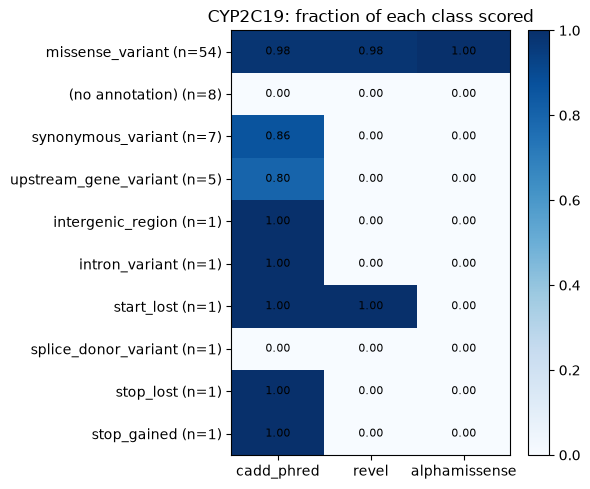

In [40]:
TOOLS = ["cadd_phred", "revel", "alphamissense"]
# (the Atlas cell runs later; if you ran it, re-run this cell afterwards with "avi" added)
if "avi" in G.columns and G["avi"].notna().any():
    TOOLS.append("avi")

cons = G.consequence.fillna("(no annotation)")
scored = G[TOOLS].notna().groupby(cons).sum()
scored.insert(0, "n_variants", cons.value_counts())
scored = scored.sort_values("n_variants", ascending=False)

frac = scored[TOOLS].div(scored.n_variants, axis=0).round(2)
print(f"Number of variants each tool could score, by consequence ({MY_GENE})\n")
print(scored.to_string())
print("\nSame thing as a fraction of the class\n")
print(frac.to_string())

print("\nOverall % scored by each tool")
for t in TOOLS:
    print(f"  {t:14s} {100*G[t].notna().mean():5.1f}%")

zero_revel = scored.index[scored.revel == 0].tolist()
no_missense = scored.index[(scored.revel == 0) & (scored.alphamissense == 0)].tolist()
print(f"\nClasses with ZERO REVEL scores: {zero_revel}")
print(f"Classes with NO missense score at all (REVEL and AlphaMissense both empty): {no_missense}")
print(f"  -> {scored.loc[no_missense, 'n_variants'].sum()} variants that a missense-only pipeline "
      "would silently skip (blank = could not score, NOT benign)")

# heatmap of the fraction scored
fig, ax = plt.subplots(figsize=(6, 0.35*len(frac) + 1.5))
im = ax.imshow(frac.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(TOOLS))); ax.set_xticklabels(TOOLS)
ax.set_yticks(range(len(frac))); ax.set_yticklabels([f"{i} (n={n})" for i, n in zip(frac.index, scored.n_variants)])
for i in range(frac.shape[0]):
    for j in range(frac.shape[1]):
        ax.text(j, i, f"{frac.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title(f"{MY_GENE}: fraction of each class scored")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


In [41]:
# Max credible allele frequency, chosen PER GENE from its known functional alleles.
# gnomad_af here is the GLOBAL frequency, so population-specific highs are diluted;
# the threshold sits comfortably above the commonest functional allele in each gene.
AF_BY_GENE = {
    "CYP2C19": 0.30,   # *2 ~15% (up to ~30% in East Asians), *17 ~20% in Europeans
    "CYP2C9":  0.15,   # *2 ~10-12% and *3 ~6-7% in Europeans
    "VKORC1":  0.60,   # -1639G>A ~40% in Europeans, majority allele in East Asians
    "DPYD":    0.05,   # *2A and c.2846A>T ~1%, HapB3 ~2-3%: rarer, toxicity alleles
    "TPMT":    0.10,   # *3C ~5% globally, higher in some African populations
}
MAX_AF = AF_BY_GENE[MY_GENE]
print(f"MAX_AF for {MY_GENE} = {MAX_AF}\n")

G_ALL = G.copy()                     # keep the unfiltered set for reference
KEEP_LABELS = ["P/LP", "other"]      # "other" is mostly drug response
show = ["rsid", "note", "consequence", "aa_change", "gnomad_af", "clinvar_sig", "label"]

def removed_by(threshold):
    return G_ALL[G_ALL.gnomad_af > threshold]     # missing AF is NOT removed

rem = removed_by(MAX_AF)
print(f"Filter at {MAX_AF}: removes {len(rem)} of {len(G_ALL)} variants "
      f"({G_ALL.gnomad_af.isna().sum()} have no gnomAD AF and are kept)")
imp = rem[rem.label.isin(KEEP_LABELS) | rem.note.notna()]
print(f"  P/LP, drug-response or anchor variants removed: {len(imp)}")
print(imp[show].to_string(index=False) if len(imp) else "  (none - good)")
if rem.note.notna().any():
    print("\n  [!] This threshold removes a known functional allele. Raise it or justify in the report.")

rem3 = removed_by(0.001)
imp3 = rem3[rem3.label.isin(KEEP_LABELS) | rem3.note.notna()]
print(f"\nCONTRAST - rare-disease filter at 0.001: removes {len(rem3)} variants, "
      f"including {len(imp3)} P/LP / drug-response / anchor variants:")
print(imp3[show].to_string(index=False) if len(imp3) else "  (none)")

G = G_ALL[~(G_ALL.gnomad_af > MAX_AF)].copy()
print(f"\nG now has {len(G)} variants after filtering")


MAX_AF for CYP2C19 = 0.3

Filter at 0.3: removes 2 of 80 variants (25 have no gnomAD AF and are kept)
  P/LP, drug-response or anchor variants removed: 0
  (none - good)

CONTRAST - rare-disease filter at 0.001: removes 19 variants, including 15 P/LP / drug-response / anchor variants:
       rsid       note           consequence aa_change  gnomad_af   clinvar_sig label
  rs7902257        NaN upstream_gene_variant       NaN   0.022133 drug response other
 rs41291556        NaN      missense_variant     W120R   0.001571         other other
 rs28399504        NaN            start_lost       M1V   0.002379 drug response other
  rs4986893        NaN           stop_gained     W212X   0.002506 drug response other
  rs4244285  CYP2C19*2    synonymous_variant       NaN   0.167953 drug response other
 rs17882687        NaN      missense_variant      I19L   0.005733 drug response other
 rs17879685        NaN      missense_variant     R410C   0.004596 drug response other
 rs17884712        NaN    

In [42]:
# CADD: the only tool that scores every consequence class (REVEL is missense-only)
SCORE_COL = "cadd_phred"
BANDS     = [0, 10, 20, 25, 30, 100]      # CADD phred can exceed 50, so top edge is 100
MIN_N     = 10                            # bands with fewer labelled variants are not evidence
MIN_PER_CLASS = 10                        # need at least this many P/LP AND B/LB to calibrate

lab = G[G.label.isin(["P/LP", "B/LB"]) & G[SCORE_COL].notna()]
n_p, n_b = (lab.label == "P/LP").sum(), (lab.label == "B/LB").sum()
print(f"{MY_GENE}: {n_p} P/LP and {n_b} B/LB variants with a {SCORE_COL} score")

CAL_SET = G
POOLED_WITH = None
if n_p < MIN_PER_CLASS or n_b < MIN_PER_CLASS:
    # small-gene route: pool with a second gene, and DISCLOSE it
    POOLED_WITH = "DPYD" if MY_GENE != "DPYD" else "CYP2C19"
    print(f"\n[!] Too few labelled variants to calibrate {MY_GENE} alone "
          f"(need >= {MIN_PER_CLASS} of each). Pooling with {POOLED_WITH}.")
    f2 = DATA / f"{POOLED_WITH}.tsv"
    G2 = pd.read_csv(f2, sep="\t") if f2.exists() else fetch_gene(POOLED_WITH)
    if not f2.exists(): G2.to_csv(f2, sep="\t", index=False)
    G2 = numeric(G2); G2["label"] = G2.clinvar_sig.map(clinvar_label)
    G2 = G2[~(G2.gnomad_af > AF_BY_GENE[POOLED_WITH])]
    CAL_SET = pd.concat([G, G2], ignore_index=True)
    lab = CAL_SET[CAL_SET.label.isin(["P/LP", "B/LB"]) & CAL_SET[SCORE_COL].notna()]
    n_p, n_b = (lab.label == "P/LP").sum(), (lab.label == "B/LB").sum()
    print(f"    pooled set: {n_p} P/LP and {n_b} B/LB")

CAL = calibrate(CAL_SET, SCORE_COL, BANDS)
CAL["reliable"] = np.where(CAL.n >= MIN_N, "yes", f"NO (n<{MIN_N})")
print(f"\nCalibration of {SCORE_COL}" + (f" (pooled {MY_GENE}+{POOLED_WITH})" if POOLED_WITH else "") + "\n")
print(CAL.to_string())

print(f"\nCalibration rests on {CAL.attrs['n_p'] + CAL.attrs['n_b']} labelled variants "
      f"({CAL.attrs['n_p']} P/LP, {CAL.attrs['n_b']} B/LB)")
small = CAL[CAL.n < MIN_N]
print(f"Bands resting on fewer than {MIN_N} variants: {len(small)} -> {[str(b) for b in small.index]}")
zero = CAL[(CAL.n_PLP == 0) | (CAL.n_BLB == 0)]
if len(zero):
    print(f"Bands with zero P/LP or zero B/LB (LR is 0 or infinite, not a real estimate): "
          f"{[str(b) for b in zero.index]}")


CYP2C19: 0 P/LP and 5 B/LB variants with a cadd_phred score

[!] Too few labelled variants to calibrate CYP2C19 alone (need >= 10 of each). Pooling with DPYD.
    pooled set: 39 P/LP and 72 B/LB

Calibration of cadd_phred (pooled CYP2C19+DPYD)

            n  n_PLP  n_BLB   LR+                evidence   reliable
band                                                                
(0, 10]    47      0     47  0.00          strong, benign        yes
(10, 20]   19      0     19  0.00          strong, benign        yes
(20, 25]   10      5      5  1.85  no evidence either way        yes
(25, 30]    4      3      1  5.54    moderate, pathogenic  NO (n<10)
(30, 100]  31     31      0   inf      strong, pathogenic        yes

Calibration rests on 111 labelled variants (39 P/LP, 72 B/LB)
Bands resting on fewer than 10 variants: 1 -> ['(25, 30]']
Bands with zero P/LP or zero B/LB (LR is 0 or infinite, not a real estimate): ['(0, 10]', '(10, 20]', '(30, 100]']


In [43]:
def band_evidence(score):
    if score != score:                                  # NaN
        return "no score (could not score)"
    b = pd.cut([score], BANDS)[0]
    if b != b or b not in CAL.index:
        return "outside calibrated range"
    row = CAL.loc[b]
    if row.n < MIN_N:
        return f"{row.evidence} - NOT applied, band n={row.n}"
    return row.evidence

def call_from(ev):
    if "NOT applied" in ev or ev.startswith(("no score", "outside", "undefined")):
        return "VUS (stays put)"
    if "pathogenic" in ev:
        return f"VUS, towards pathogenic (PP3 {ev.split(',')[0]})"
    if "benign" in ev and "either" not in ev:
        return f"VUS, towards benign (BP4 {ev.split(',')[0]})"
    return "VUS (stays put)"

V = G[G.label == "VUS"].copy()
V["evidence"] = V[SCORE_COL].map(band_evidence)
V["provisional_call"] = V.evidence.map(call_from)

n_path = V.provisional_call.str.contains("pathogenic").sum()
n_ben  = V.provisional_call.str.contains("benign").sum()
n_stay = len(V) - n_path - n_ben
print(f"{len(V)} VUS in {MY_GENE}")
print(f"  towards pathogenic: {n_path}")
print(f"  towards benign:     {n_ben}")
print(f"  stay put:           {n_stay}")
print("\nbreakdown of evidence assigned:")
print(V.evidence.value_counts().to_string())

OUT = f"pgx_classified_{MY_GENE}.csv"
V[["rsid", "gene", "consequence", "aa_change", SCORE_COL, "gnomad_af",
   "evidence", "provisional_call"]].to_csv(OUT, index=False)
print(f"\nexported {len(V)} rows to {OUT}")
print("(a 'towards' call is ONE piece of computational evidence, not a reclassification)")


33 VUS in CYP2C19
  towards pathogenic: 0
  towards benign:     16
  stay put:           17

breakdown of evidence assigned:
evidence
strong, benign                                  16
no evidence either way                           8
no score (could not score)                       6
moderate, pathogenic - NOT applied, band n=4     3

exported 33 rows to pgx_classified_CYP2C19.csv
(a 'towards' call is ONE piece of computational evidence, not a reclassification)


In [44]:
SKIP_ATLAS   = True
MAX_VARIANTS = 200

import os
ATLAS_STATUS = "not run"

def to_variant_string(hgvs):
    """Atlas wants 1-based GRCh38 chr:pos:ref>alt. It does NOT accept rsIDs."""
    m = re.match(r"(chr[\w]+):g\.(\d+)([ACGT])>([ACGT])", str(hgvs))
    return f"{m.group(1)}:{m.group(2)}:{m.group(3)}>{m.group(4)}" if m else None

if SKIP_ATLAS:
    print("SKIPPED. Disclose this in your report and answer Q6.2 from reasoning.")
    ATLAS_STATUS = "skipped"
else:
    try:
        from alphagenome.atlas import atlas
        from alphagenome.data import genome
        key = os.environ.get("ALPHAGENOME_API_KEY") or os.environ.get("ALPHA_GENOME_API_KEY")
        if not key:
            raise RuntimeError(
                "No API key in your environment. Did you relaunch Jupyter from a NEW\n"
                "  terminal after setting it? Check with:\n"
                "    import os; print(os.environ.get('ALPHAGENOME_API_KEY'))\n"
                "  Or set SKIP_ATLAS = True.")
        client = atlas.create(key, timeout=30)

        pri = G.assign(_nc=~G.consequence.fillna("").str.contains("missense")) \
               .sort_values("_nc", ascending=False).head(MAX_VARIANTS)
        rows, errs = [], 0
        for n, (_, r) in enumerate(pri.iterrows(), 1):
            vs = to_variant_string(r.hgvs_g)
            if not vs:
                continue
            try:
                res = client.query_variant(
                    genome.Variant.from_str(vs),
                    requested_scorers=["AVI_SCORE", "AVI_SCORE_FEATURE_IMPORTANCE"])
                ad = res["AVI_SCORE"]
                cdf = float(ad.layers["quantiles"][0, 0])
                fi = res["AVI_SCORE_FEATURE_IMPORTANCE"]
                rows.append({"rsid": r.rsid,
                             "avi_phred": round(-10*np.log10(max(1-cdf, 1e-12)), 2),
                             "top_feature": fi.var["name"].values[int(np.argmax(np.abs(fi.X[0])))]})
            except Exception:
                errs += 1
            if n % 50 == 0:
                print(f"  {n}/{len(pri)} queried", flush=True)

        avi = pd.DataFrame(rows)
        if len(avi):
            avi.to_csv(DATA / f"avi_{MY_GENE}.tsv", sep="\t", index=False)
            G = G.merge(avi, on="rsid", how="left")
            G["avi"] = G.avi_phred
            ATLAS_STATUS = "queried live"
            print(f"\nscored {len(avi)} variants ({errs} failures)")
    except ImportError:
        print('alphagenome not installed. pip install "alphagenome>=0.9.0", then restart.')
        print("Or set SKIP_ATLAS = True.")
    except Exception as e:
        print(f"{type(e).__name__}: {e}")

if "avi" not in G.columns: G["avi"] = np.nan
if "top_feature" not in G.columns: G["top_feature"] = np.nan
G["avi"] = pd.to_numeric(G["avi"], errors="coerce")

if G.avi.notna().sum() > 0:
    a = G[G.avi.notna()]
    cols = [c for c in ["rsid", "consequence", "avi_phred", "top_feature",
                        "revel", "cadd_phred", "label"] if c in a.columns]
    print(f"\nhighest-impact {MY_GENE} variants by AVI\n")
    print(a.sort_values("avi", ascending=False)[cols].head(10).to_string(index=False))
    print("\nwhat is driving the scores (read this BEFORE the numbers)")
    print(a.top_feature.value_counts().head(8).to_string())
else:
    nc = G[~G.consequence.fillna("").str.contains("missense")]
    print(f"\nnon-missense variants in {MY_GENE}, which is what the Atlas is for: {len(nc)}")
    print(nc.consequence.value_counts().to_string())

print(f"\n[Atlas status: {ATLAS_STATUS}]")

SKIPPED. Disclose this in your report and answer Q6.2 from reasoning.

non-missense variants in CYP2C19, which is what the Atlas is for: 25
consequence
synonymous_variant       6
upstream_gene_variant    5
start_lost               1
stop_gained              1
intron_variant           1
splice_donor_variant     1
stop_lost                1
intergenic_region        1

[Atlas status: skipped]


In [45]:
d = G.copy()
coding = d.consequence.isin(["missense_variant", "synonymous_variant"])

d["flag_cadd_vs_revel"]  = (d.cadd_phred > 25) & (d.revel < 0.35)
d["flag_revel_vs_am"]    = (d.revel - d.alphamissense).abs() > 0.4
d["flag_scored_but_vus"] = (d.label == "VUS") & (d.revel > 0.7)
d["flag_common_but_plp"] = (d.gnomad_af > 0.01) & (d.label.isin(["P/LP", "other"]))
d["flag_no_tool_at_all"] = d[["revel", "alphamissense", "cadd_phred"]].isna().all(axis=1)
if d.avi.notna().any():
    d["flag_atlas_only"] = (d.avi > 20) & d.revel.isna() & d.alphamissense.isna()

flags = [c for c in d.columns if c.startswith("flag_")]
print(f"discordant variants in {MY_GENE}\n")
print(d[flags].sum().to_string())

hits = d[d[flags].any(axis=1)]
cols = [c for c in ["rsid", "note", "consequence", "consequence_all", "aa_change",
                    "cadd_phred", "revel", "alphamissense", "avi", "gnomad_af",
                    "label"] if c in d.columns]
print(f"\n{len(hits)} variants trip at least one rule\n")
print(hits[cols].head(15).to_string(index=False) if len(hits) else "  (none)")

if len(hits) == 0:
    print("\nNone. That is a legitimate result. Say so in your report and explain why")
    print("this gene's variants are concordant, rather than loosening the rules until")
    print("something fires.")

discordant variants in CYP2C19

flag_cadd_vs_revel      3
flag_revel_vs_am        6
flag_scored_but_vus     0
flag_common_but_plp     4
flag_no_tool_at_all    10

21 variants trip at least one rule

       rsid      note           consequence                         consequence_all aa_change  cadd_phred  revel  alphamissense  avi  gnomad_af label
        NaN       NaN                   NaN                                     NaN       NaN         NaN    NaN            NaN  NaN        NaN   VUS
  rs7902257       NaN upstream_gene_variant intergenic_region;upstream_gene_variant       NaN         NaN    NaN            NaN  NaN   0.022133 other
        NaN       NaN                   NaN                                     NaN       NaN         NaN    NaN            NaN  NaN        NaN  B/LB
 rs41291556       NaN      missense_variant                        missense_variant     W120R      25.700  0.440         0.9402  NaN   0.001571 other
rs145328984       NaN      missense_variant        